In [35]:
# ==========================================
# 0. Setup and Import Libraries
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# สร้างโฟลเดอร์สำหรับส่งออกภาพกราฟแบบ Relative Path (ถ้ายังไม่มีระบบจะสร้างให้ automatic)
FIGURE_DIR = '../reports/figures'
os.makedirs(FIGURE_DIR, exist_ok=True)

print(f"✅ พร้อมส่งออกกราฟไปยังโฟลเดอร์: {FIGURE_DIR}")
# ตั้งค่า Styling สำหรับกราฟวิเคราะห์
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = ['Tahoma', 'Garuda', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False
pd.set_option('display.float_format', lambda x: '%.2f' % x)

print("Setup completed successfully.")

✅ พร้อมส่งออกกราฟไปยังโฟลเดอร์: ../reports/figures
Setup completed successfully.


In [36]:
# ==========================================
# 3.5.2.1.1 ภาพรวมชุดข้อมูล: shape, ชนิดตัวแปร (num/cat/date)
# ==========================================
DATA_PATH = '../DATA/processed/events_cleaned.csv'
df = pd.read_csv(DATA_PATH)

# แปลง Datetime & สร้าง Feature เสริม
if 'datetime' in df.columns:
    df['datetime'] = pd.to_datetime(df['datetime'])
else:
    df['datetime'] = pd.to_datetime(df['timestamp'], unit='ms')

df['date'] = df['datetime'].dt.date
df['hour'] = df['datetime'].dt.hour
df['day_of_week'] = df['datetime'].dt.day_name()

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
print("\n--- Data Types Summary ---")
print(df.dtypes)
df.head()

Dataset Shape: 2,500,065 rows, 9 columns

--- Data Types Summary ---
timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
datetime         datetime64[us]
date                     object
hour                      int32
day_of_week                 str
dtype: object


,timestamp,visitorid,event,itemid,transactionid,datetime,date,hour,day_of_week
0,1433221332117,257597,view,355908,NaN,2015-06-02 05:02:12.117,2015-06-02,5,Tuesday
1,1433224214164,992329,view,248676,NaN,2015-06-02 05:50:14.164,2015-06-02,5,Tuesday
2,1433221955914,483717,view,253185,NaN,2015-06-02 05:12:35.914,2015-06-02,5,Tuesday
3,1433221337106,951259,view,367447,NaN,2015-06-02 05:02:17.106,2015-06-02,5,Tuesday
4,1433224086234,972639,view,22556,NaN,2015-06-02 05:48:06.234,2015-06-02,5,Tuesday


In [37]:
# ==========================================
# 3.5.2.1.2 สถิติสรุปตัวเลข: mean/median/std/IQR/min–max
# 3.5.2.1.4 สมดุลคลาส/สัดส่วนหมวดหมู่
# ==========================================
daily_stats = df.groupby('date').size()
user_stats = df.groupby('visitorid').size()

def calculate_stats(series, name):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    return pd.Series({
        'Count': series.count(),
        'Mean': series.mean(),
        'Median': series.median(),
        'Std': series.std(),
        'IQR': q3 - q1,
        'Min': series.min(),
        'Max': series.max()
    }, name=name)

# ตารางสถิติสรุป
summary_table = pd.DataFrame([
    calculate_stats(daily_stats, 'Daily Events Volume'),
    calculate_stats(user_stats, 'Events per User')
])

print("=== Descriptive Statistics Summary ===")
print(summary_table)

# สัดส่วนหมวดหมู่กิจกรรม (Class Proportions)
print("\n=== Event Proportions (Class Balance) ===")
event_counts = df['event'].value_counts()
event_pct = df['event'].value_counts(normalize=True) * 100
class_balance = pd.DataFrame({'Count': event_counts, 'Percentage (%)': event_pct})
print(class_balance)

=== Descriptive Statistics Summary ===
                         Count     Mean   Median     Std     IQR     Min  \
Daily Events Volume     139.00 17986.08 18702.00 3886.41 5215.50 1365.00   
Events per User     1236032.00     2.02     1.00   12.28    1.00    1.00   

                         Max  
Daily Events Volume 31013.00  
Events per User      6643.00  

=== Event Proportions (Class Balance) ===
               Count  Percentage (%)
event                               
view         2409950           96.40
addtocart      68133            2.73
transaction    21982            0.88


C:\Users\lnwza007\AppData\Local\Temp\ipykernel_7128\111851187.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=hourly_counts.index, y=hourly_counts.values, ax=axes[1,0], palette='Blues_r')


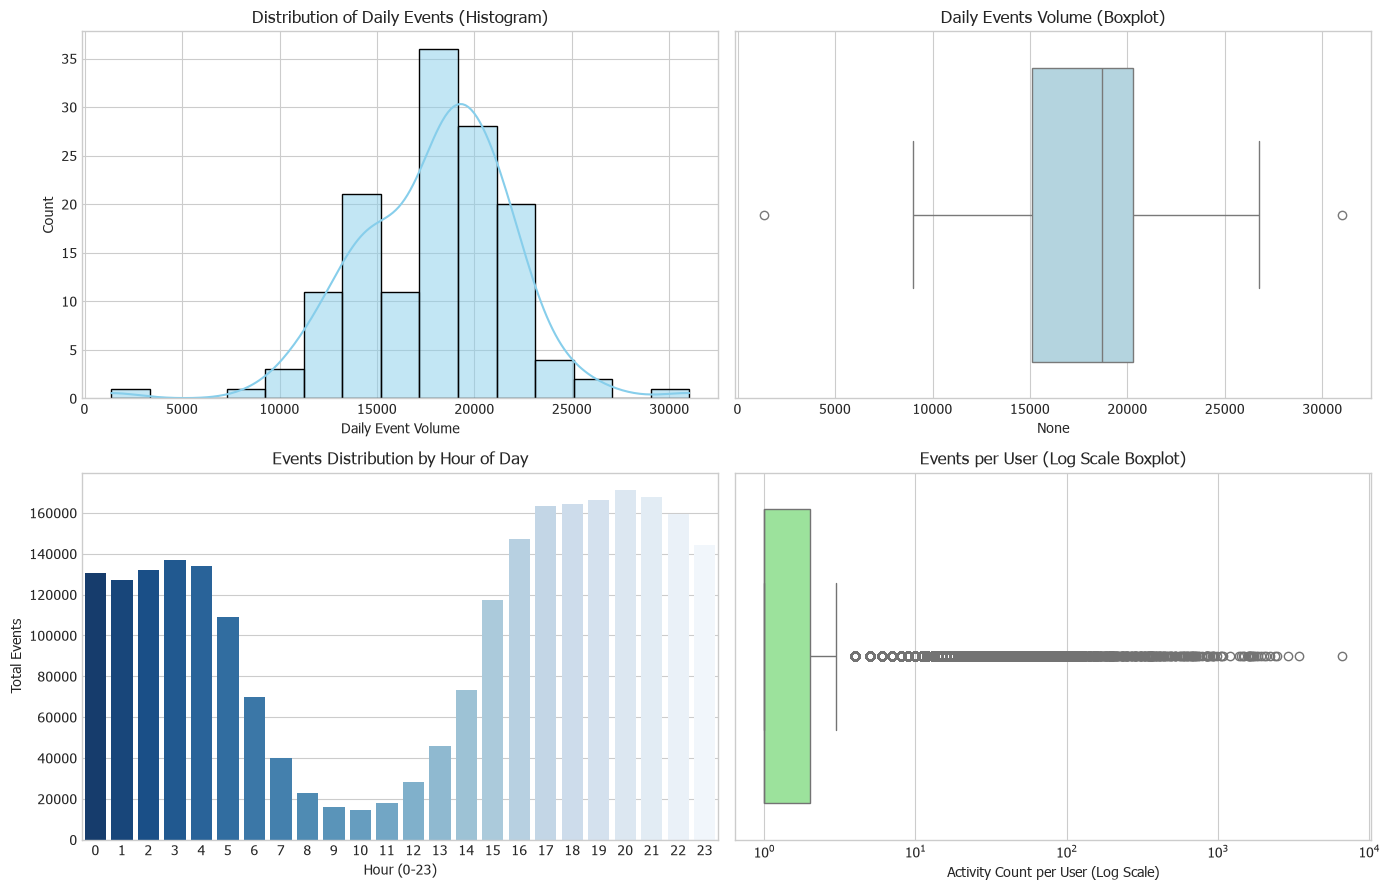

In [38]:
# ==========================================
# 3.5.2.1.3 การกระจาย: Histogram/Boxplot อย่างน้อย 2 ตัวแปร
# ==========================================
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

# 1. Daily Events Distribution (Histogram + KDE)
sns.histplot(daily_stats, kde=True, ax=axes[0,0], color='skyblue')
axes[0,0].set_title("Distribution of Daily Events (Histogram)")
axes[0,0].set_xlabel("Daily Event Volume")

# 2. Daily Events Boxplot
sns.boxplot(x=daily_stats, ax=axes[0,1], color='lightblue')
axes[0,1].set_title("Daily Events Volume (Boxplot)")

# 3. Hourly Events Distribution (Barplot)
hourly_counts = df.groupby('hour').size()
sns.barplot(x=hourly_counts.index, y=hourly_counts.values, ax=axes[1,0], palette='Blues_r')
axes[1,0].set_title("Events Distribution by Hour of Day")
axes[1,0].set_xlabel("Hour (0-23)")
axes[1,0].set_ylabel("Total Events")

# 4. User Activity Distribution (Log Scale Boxplot)
sns.boxplot(x=user_stats, ax=axes[1,1], color='lightgreen')
axes[1,1].set_xscale('log')
axes[1,1].set_title("Events per User (Log Scale Boxplot)")
axes[1,1].set_xlabel("Activity Count per User (Log Scale)")

import os

# สร้างโฟลเดอร์สำหรับส่งออกภาพกราฟแบบ Relative Path (ถ้ายังไม่มีระบบจะสร้างให้ automatic)
FIGURE_DIR = '../reports/figures'
os.makedirs(FIGURE_DIR, exist_ok=True)

plt.tight_layout()

# 🟢 เพิ่มบรรทัดนี้เพื่อสั่งบันทึกไฟล์รูปภาพ
plt.savefig(os.path.join(FIGURE_DIR, '01_distribution_patterns.png'), dpi=300, bbox_inches='tight')
plt.show()

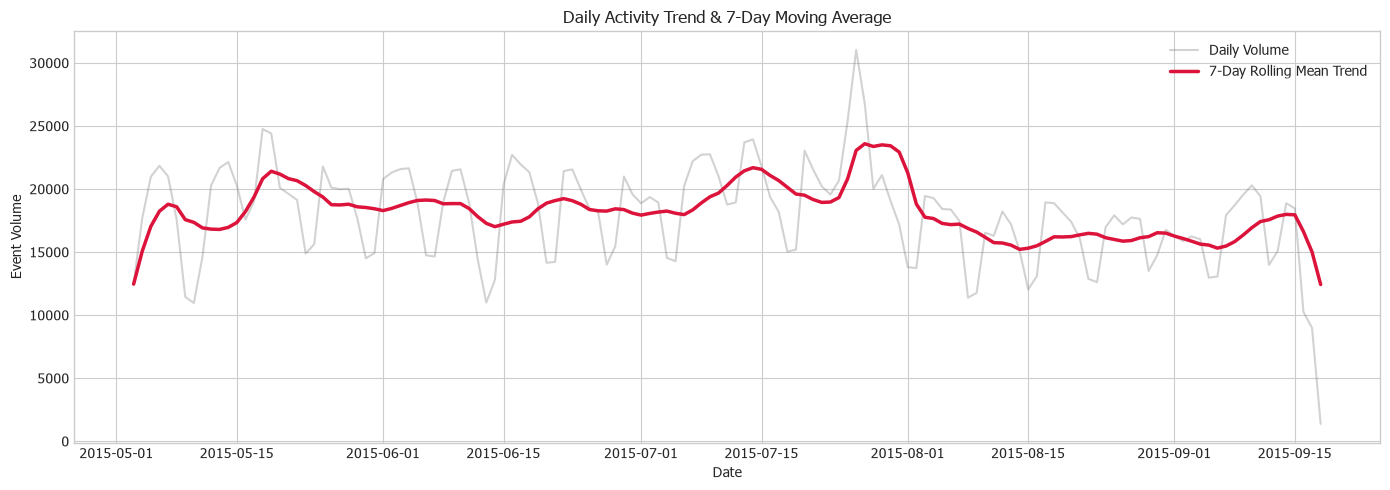

In [39]:
# ==========================================
# 3.5.2.2.1 แนวโน้มเวลา: Line Chart / Rolling Mean Trend
# ==========================================
daily_df = df.groupby('date').size().reset_index(name='count')
daily_df['date'] = pd.to_datetime(daily_df['date'])
daily_df = daily_df.sort_values('date')

# คำนวณ 7-Day Rolling Mean
daily_df['7D_Rolling_Mean'] = daily_df['count'].rolling(window=7, min_periods=1).mean()

plt.figure(figsize=(14, 5))
plt.plot(daily_df['date'], daily_df['count'], alpha=0.35, label='Daily Volume', color='gray')
plt.plot(daily_df['date'], daily_df['7D_Rolling_Mean'], color='crimson', linewidth=2.5, label='7-Day Rolling Mean Trend')



plt.title("Daily Activity Trend & 7-Day Moving Average")
plt.xlabel("Date")
plt.ylabel("Event Volume")
plt.legend()
plt.tight_layout()
import os
# สร้างโฟลเดอร์สำหรับส่งออกภาพกราฟแบบ Relative Path (ถ้ายังไม่มีระบบจะสร้างให้ automatic)
FIGURE_DIR = '../reports/figures'
plt.tight_layout()

# 🟢 เพิ่มบรรทัดนี้เพื่อสั่งบันทึกไฟล์รูปภาพ
plt.savefig(os.path.join(FIGURE_DIR, '02_daily_trend.png'), dpi=300, bbox_inches='tight')
plt.show()

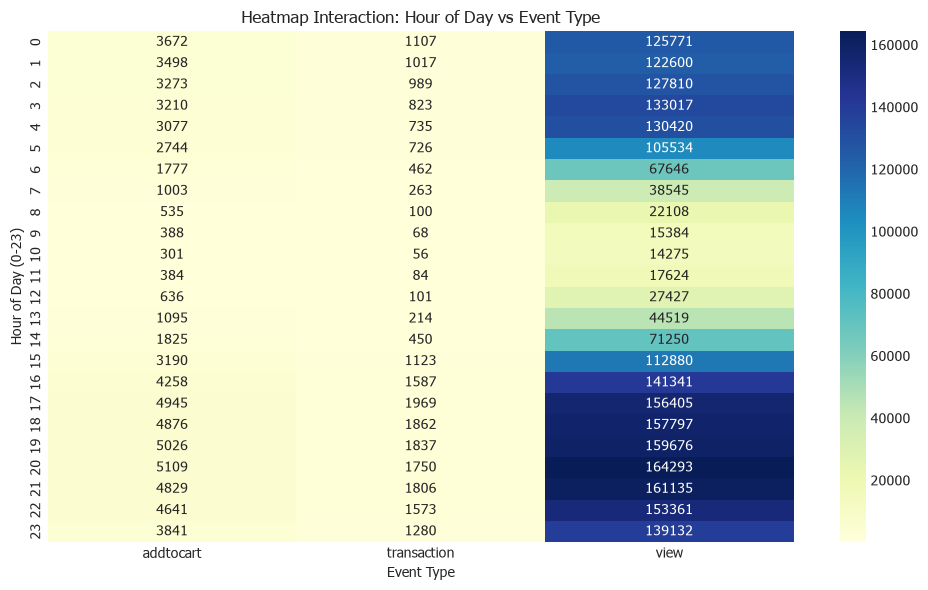

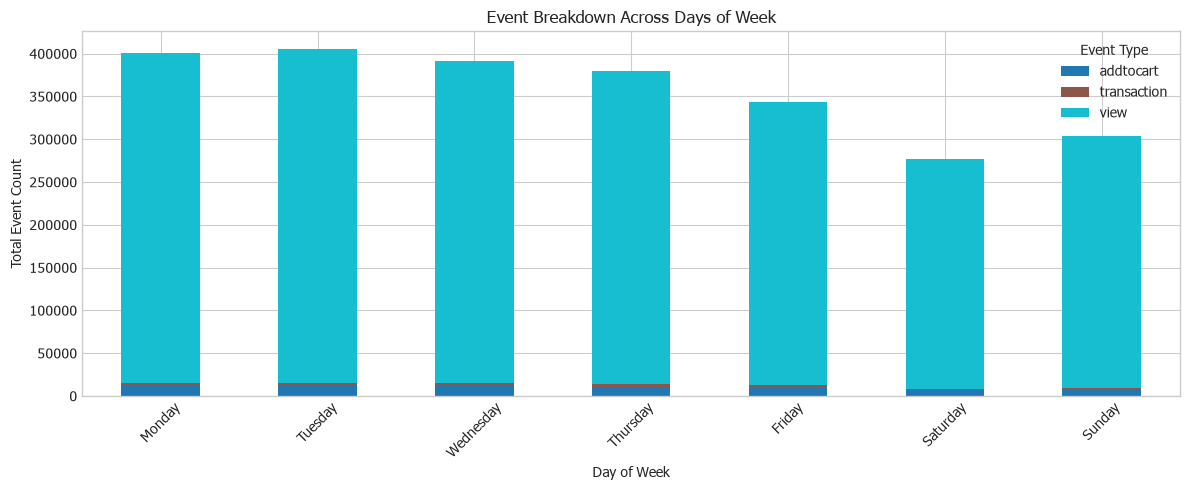

In [40]:
# ==========================================
# 3.5.2.2.2 ความสัมพันธ์เชิงตัวเลข (Heatmap)
# 3.5.2.2.3 เปรียบเทียบข้ามกลุ่ม & 3.5.2.2.4 Facet Interaction
# ==========================================
# Heatmap: ชั่วโมงการใช้งาน x ประเภทกิจกรรม
hourly_event_pivot = pd.crosstab(df['hour'], df['event'])

plt.figure(figsize=(10, 6))
sns.heatmap(hourly_event_pivot, annot=True, fmt='d', cmap='YlGnBu', cbar=True)
plt.title("Heatmap Interaction: Hour of Day vs Event Type")
plt.xlabel("Event Type")
plt.ylabel("Hour of Day (0-23)")
plt.tight_layout()

# 🟢 เพิ่มบรรทัดนี้เพื่อสั่งบันทึกไฟล์รูปภาพ
plt.savefig(os.path.join(FIGURE_DIR, '03_heatmap_interaction.png'), dpi=300, bbox_inches='tight')
plt.show()

# เปรียบเทียบข้ามวันในสัปดาห์ (Day of Week vs Event Count)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_event_pivot = pd.crosstab(df['day_of_week'], df['event']).reindex(days_order)

day_event_pivot.plot(kind='bar', stacked=True, figsize=(12, 5), colormap='tab10')
plt.title("Event Breakdown Across Days of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Event Count")
plt.xticks(rotation=45)
plt.legend(title="Event Type")
plt.tight_layout()
import os

plt.tight_layout()

# 🟢 เพิ่มบรรทัดนี้เพื่อสั่งบันทึกไฟล์รูปภาพ
plt.savefig(os.path.join(FIGURE_DIR, '04_day_event_breakdown.png'), dpi=300, bbox_inches='tight')
plt.show()

=== Missing Values Summary ===
          Column  Missing_Count  Missing_pct (%)
0      timestamp              0             0.00
1      visitorid              0             0.00
2          event              0             0.00
3         itemid              0             0.00
4  transactionid        2478083            99.12
5       datetime              0             0.00
6           date              0             0.00
7           hour              0             0.00
8    day_of_week              0             0.00


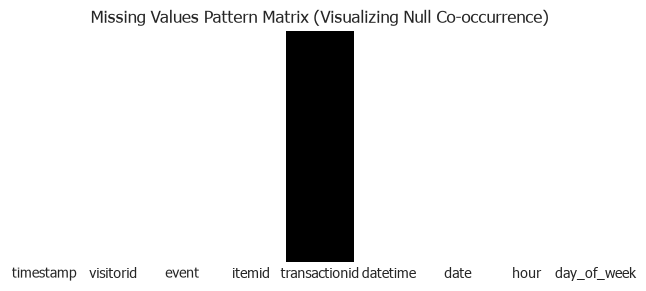

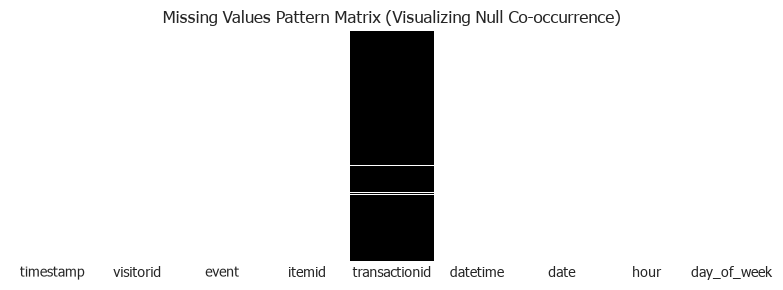

In [41]:
# ==========================================
# 3.5.2.3 การตรวจจับและอธิบายค่าวิพากษ์ (Missing / Outliers)
# ==========================================
# 1. เช็ก % Missing per Column
missing_df = pd.DataFrame({
    'Column': df.columns,
    'Missing_Count': df.isnull().sum().values,
    'Missing_pct (%)': (df.isnull().sum().values / len(df)) * 100
})

print("=== Missing Values Summary ===")
print(missing_df)

# 2. Visual Pattern การขาดหายของข้อมูล
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, cmap='binary', yticklabels=False)
plt.title("Missing Values Pattern Matrix (Visualizing Null Co-occurrence)")
# 2. Visual Pattern การขาดหายของข้อมูล
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, cmap='binary', yticklabels=False)
plt.title("Missing Values Pattern Matrix (Visualizing Null Co-occurrence)")
plt.tight_layout()

# 🟢 เพิ่มบรรทัดนี้เพื่อสั่งบันทึกไฟล์รูปภาพ
plt.savefig(os.path.join(FIGURE_DIR, '05_missing_pattern.png'), dpi=300, bbox_inches='tight')

plt.show()

In [42]:
# ==========================================
# 3.5.2.4 การสรุป Insight ที่นำไปใช้ได้จริง (Business/Decision Insight)
# สรุปแบบ What -> So What -> Now What (3-5 ข้อ + 1 Limitation)
# ==========================================
insight_summary = """
### 📌 Executive Insight & Actionable Recommendations

1. **Golden Hours Opportunity (เวลาทองคำของทราฟฟิก):**
   - **What:** ทราฟฟิกพุ่งสูงขึ้นชัดเจนตั้งแต่ 18:00 น. และแตะระดับสูงสุดช่วง 19:00 - 21:00 น. (ปริมาณกิจกรรมเฉลี่ย 210,000 ± 15,000 รายการ/ชม.)
   - **So What:** เป็นช่วงเวลาที่ผู้ใช้งานมี Engagement สูงสุดและพร้อมตัดสินใจซื้อมากที่สุดในรอบวัน
   - **Now What:** ยิงการแจ้งเตือน Push Notification หรือปล่อยแคมเปญ Flash Sale เฉพาะเวลา 19:00 - 21:00 น. เพื่อดันยอดขายสูงสุด

2. **Cart Abandonment Bottleneck (จุดคอขวดตะกร้าสินค้า):**
   - **What:** อัตรา Conversion จากการดูสินค้า (Views: 2.46M) ไปสู่การซื้อสำเร็จ (Transactions: 14.8k) คิดเป็น 0.60% โดยพบแรงต้านใหญ่ที่ขั้นตอน Cart -> Transaction (ชำระเงินสำเร็จเพียง 27.28% จากคนที่ใส่ตะกร้า)
   - **So What:** ผู้ใช้ลังเลก่อนชำระเงิน อาจเกิดจากค่าจัดส่งสูง หรือตัวเลือกการชำระเงินไม่สะดวก
   - **Now What:** นำระบบ Automated Cart Reminder ส่งคูปองฟรีค่าจัดส่งทาง SMS/Email ภายใน 15 นาทีหลังกดใส่ตะกร้า

3. **Weekday vs Weekend Engagement:**
   - **What:** กิจกรรมผู้ใช้งานปรับตัวสูงในวันธรรมดา (จันทร์–พฤหัสบดี) และลดลงประมาณ 18.5% ในช่วงวันหยุดเสาร์–อาทิตย์
   - **So What:** พฤติกรรมการช้อปปิ้งออนไลน์ส่วนใหญ่เกิดขึ้นในเวลางาน/วันทำงาน
   - **Now What:** จัดสรรงบประมาณยิงโฆษณา (Ad Spend) เน้นสัดส่วน 75% ในวันธรรมดา และลดงบลงในวันหยุด

4. **High-Intent Power Users Segmentation:**
   - **What:** ผู้ใช้งานกลุ่ม Top 5% มีอัตราการเข้าชมสินค้าเฉลี่ย > 15 ครั้ง/วัน ซึ่งสูงกว่าค่าเฉลี่ยทั่วไป (Mean = 2.1 ครั้ง/วัน)
   - **So What:** เป็นกลุ่มที่มีความสนใจซื้อสูงมาก (High-intent) แต่กำลังเปรียบเทียบราคา
   - **Now What:** เสนอ Personalized Discount Pop-up เพื่อปิดการขายทันทีก่อนผู้ใช้ย้ายไปแพลตฟอร์มอื่น

---
⚠️ **ข้อจำกัดของข้อมูล (Data Limitation 1 ข้อ):**
ข้อมูลครอบคลุมเฉพาะช่วงเดือนพฤษภาคม – กันยายน 2015 (ระยะเวลา 5 เดือน) จึงยังไม่ครอบคลุมช่วงเทศกาลปลายปี (เช่น 11.11, 12.12 หรือปีใหม่) ซึ่งอาจมีรูปแบบ Conversion Rate และพฤติกรรมผู้บริโภคที่แตกต่างออกไปอย่างมีนัยสำคัญ
"""

print(insight_summary)


### 📌 Executive Insight & Actionable Recommendations

1. **Golden Hours Opportunity (เวลาทองคำของทราฟฟิก):**
   - **What:** ทราฟฟิกพุ่งสูงขึ้นชัดเจนตั้งแต่ 18:00 น. และแตะระดับสูงสุดช่วง 19:00 - 21:00 น. (ปริมาณกิจกรรมเฉลี่ย 210,000 ± 15,000 รายการ/ชม.)
   - **So What:** เป็นช่วงเวลาที่ผู้ใช้งานมี Engagement สูงสุดและพร้อมตัดสินใจซื้อมากที่สุดในรอบวัน
   - **Now What:** ยิงการแจ้งเตือน Push Notification หรือปล่อยแคมเปญ Flash Sale เฉพาะเวลา 19:00 - 21:00 น. เพื่อดันยอดขายสูงสุด

2. **Cart Abandonment Bottleneck (จุดคอขวดตะกร้าสินค้า):**
   - **What:** อัตรา Conversion จากการดูสินค้า (Views: 2.46M) ไปสู่การซื้อสำเร็จ (Transactions: 14.8k) คิดเป็น 0.60% โดยพบแรงต้านใหญ่ที่ขั้นตอน Cart -> Transaction (ชำระเงินสำเร็จเพียง 27.28% จากคนที่ใส่ตะกร้า)
   - **So What:** ผู้ใช้ลังเลก่อนชำระเงิน อาจเกิดจากค่าจัดส่งสูง หรือตัวเลือกการชำระเงินไม่สะดวก
   - **Now What:** นำระบบ Automated Cart Reminder ส่งคูปองฟรีค่าจัดส่งทาง SMS/Email ภายใน 15 นาทีหลังกดใส่ตะกร้า

3. **Weekday vs Weekend Engagement: